In [1]:
print("CreditScope - Feature Selection")

CreditScope - Feature Selection


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../Data/Credit_Cleaned.csv")

print(df.shape)
print(df.head())

(400, 11)
    income  credit_limit  credit_rating  num_cards  age  education_years  \
0   14.891          3606            283          2   34               11   
1  106.025          6645            483          3   82               15   
2  104.593          7075            514          4   71               11   
3  148.924          9504            681          3   36               11   
4   55.882          4897            357          2   68               16   

   is_homeowner  is_student  is_married region  balance  
0             0           0           1  south      333  
1             1           1           1   west      903  
2             0           0           0   west      580  
3             1           0           0   west      964  
4             0           0           1  south      331  


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   income           400 non-null    float64
 1   credit_limit     400 non-null    int64  
 2   credit_rating    400 non-null    int64  
 3   num_cards        400 non-null    int64  
 4   age              400 non-null    int64  
 5   education_years  400 non-null    int64  
 6   is_homeowner     400 non-null    int64  
 7   is_student       400 non-null    int64  
 8   is_married       400 non-null    int64  
 9   region           400 non-null    str    
 10  balance          400 non-null    int64  
dtypes: float64(1), int64(9), str(1)
memory usage: 34.5 KB

Missing Values:
income             0
credit_limit       0
credit_rating      0
num_cards          0
age                0
education_years    0
is_homeowner       0
is_student         0
is_married         0
region             0
b

In [5]:
# Calculate correlations with the target variable

correlations = df.corr(numeric_only=True)['balance'].sort_values(
    ascending=False
)

print("Correlation with Balance:")
print(correlations)

Correlation with Balance:
balance            1.000000
credit_rating      0.863625
credit_limit       0.861697
income             0.463656
is_student         0.259018
num_cards          0.086456
is_homeowner       0.021474
age                0.001835
is_married        -0.005673
education_years   -0.008062
Name: balance, dtype: float64


Matplotlib is building the font cache; this may take a moment.


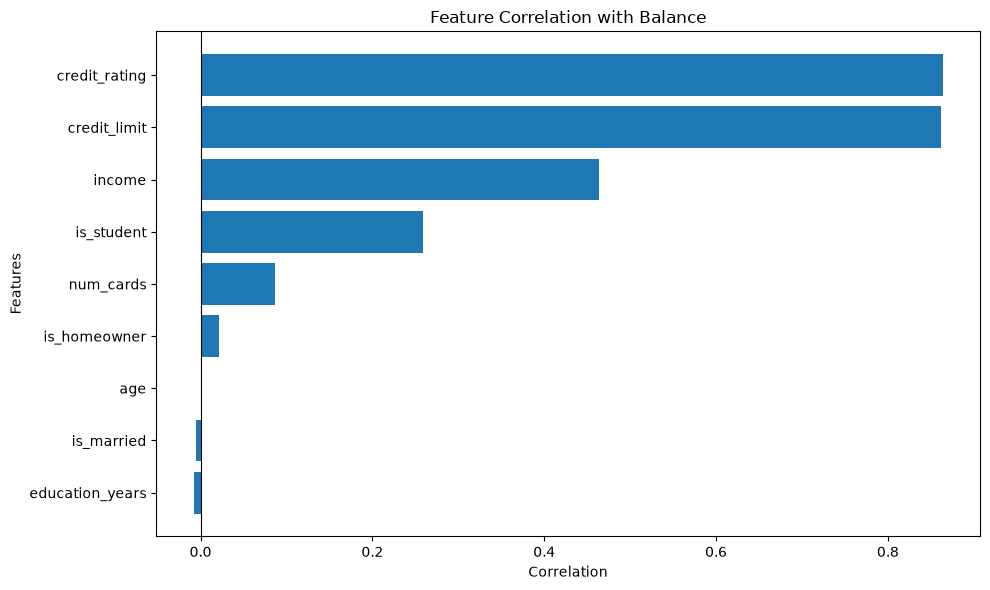

In [6]:
import matplotlib.pyplot as plt

feature_corr = correlations.drop("balance").sort_values()

plt.figure(figsize=(10, 6))

plt.barh(feature_corr.index, feature_corr.values)

plt.title("Feature Correlation with Balance")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [7]:
from sklearn.feature_selection import mutual_info_regression

X = df.drop(columns=["balance", "region"])
y = df["balance"]

mi_scores = mutual_info_regression(X, y, random_state=42)

mi_results = pd.Series(
    mi_scores,
    index=X.columns
).sort_values(ascending=False)

print("Mutual Information Scores:")
print(mi_results)

Mutual Information Scores:
credit_rating      0.858240
credit_limit       0.853793
income             0.086731
is_homeowner       0.053283
num_cards          0.043998
is_student         0.025591
education_years    0.016602
is_married         0.013214
age                0.010270
dtype: float64


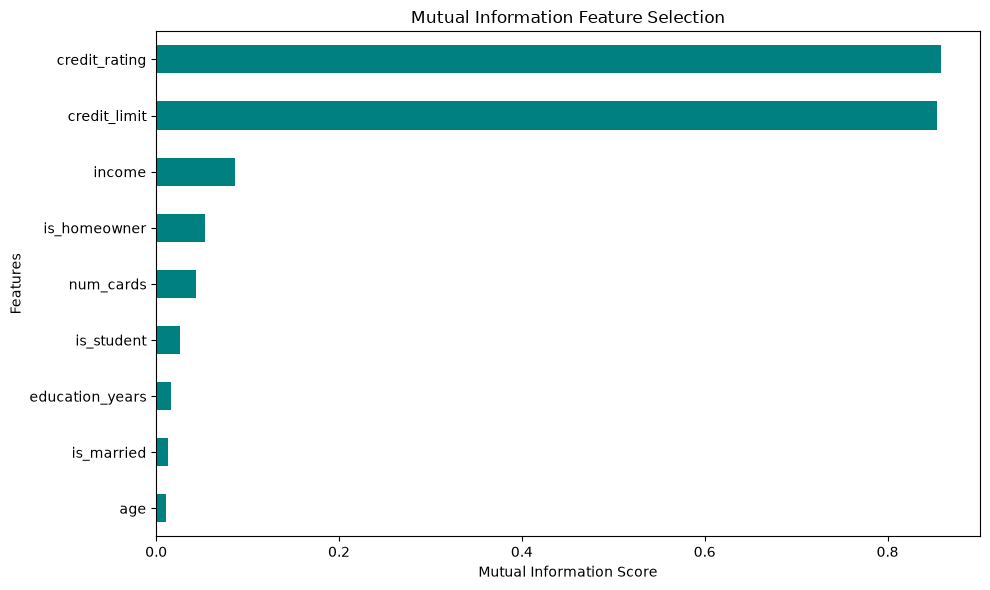

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

mi_results.sort_values().plot(
    kind="barh",
    color="teal"
)

plt.title("Mutual Information Feature Selection")
plt.xlabel("Mutual Information Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [9]:
# Select the target variable
target = "balance"

# Select the most informative features
selected_features = [
    "credit_rating",
    "credit_limit",
    "income",
    "is_student",
    "num_cards"
]

print("Selected Features:")
print(selected_features)

print("\nTarget Variable:")
print(target)

Selected Features:
['credit_rating', 'credit_limit', 'income', 'is_student', 'num_cards']

Target Variable:
balance


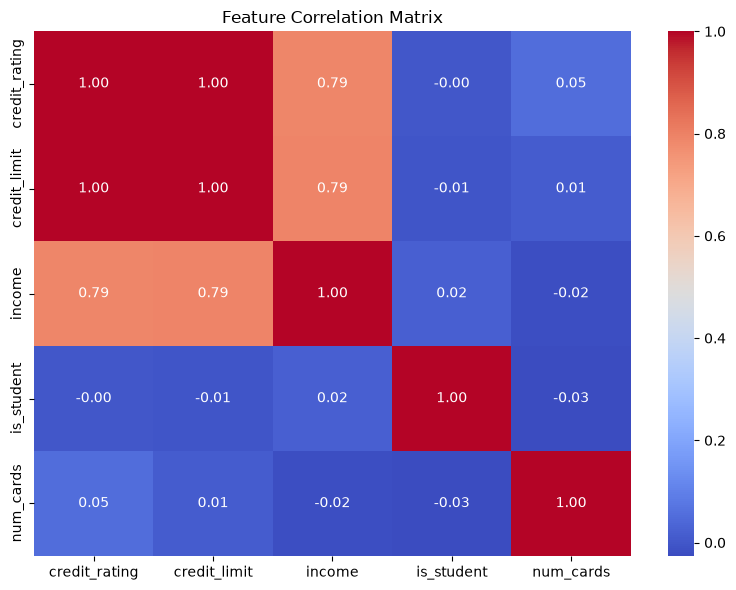

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df[selected_features].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [12]:
selected_features = [
    "credit_limit",
    "income",
    "is_student",
    "num_cards"
]

target = "balance"

print("Final Selected Features:")
print(selected_features)

print("\nTarget Variable:")
print(target)

Final Selected Features:
['credit_limit', 'income', 'is_student', 'num_cards']

Target Variable:
balance


In [13]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd

X = df[selected_features]

vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns
vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data)

        Feature       VIF
0  credit_limit  2.691449
1        income  2.692966
2    is_student  1.002234
3     num_cards  1.002574


In [14]:
final_df = df[selected_features + [target]]

final_df.to_csv(
    "../Data/Feature_Selected.csv",
    index=False
)

print("Feature Selection completed successfully!")
print(final_df.head())
print("Shape:", final_df.shape)

Feature Selection completed successfully!
   credit_limit   income  is_student  num_cards  balance
0          3606   14.891           0          2      333
1          6645  106.025           1          3      903
2          7075  104.593           0          4      580
3          9504  148.924           0          3      964
4          4897   55.882           0          2      331
Shape: (400, 5)
